In [2]:
import os
import logging
logging.getLogger('tensorflow').setLevel(logging.ERROR)

import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import confusion_matrix, classification_report

print("✓ All libraries imported successfully")

# Set visualization style
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

✓ All libraries imported successfully


In [3]:
import os
dataset_path = 'garbage-classification/Garbage classification/Garbage classification'
contents = os.listdir(dataset_path)
print(f"Contents of Garbage classification: {contents}")
for item in contents:
    item_path = os.path.join(dataset_path, item)
    if os.path.isdir(item_path):
        sub_contents = os.listdir(item_path)
        print(f"  {item} is a folder with {len(sub_contents)} images: {sub_contents[:3]}")
    else:
        print(f"  {item} is a file")

Contents of Garbage classification: ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']
  cardboard is a folder with 403 images: ['cardboard1.jpg', 'cardboard10.jpg', 'cardboard100.jpg']
  glass is a folder with 501 images: ['glass1.jpg', 'glass10.jpg', 'glass100.jpg']
  metal is a folder with 410 images: ['metal1.jpg', 'metal10.jpg', 'metal100.jpg']
  paper is a folder with 594 images: ['paper1.jpg', 'paper10.jpg', 'paper100.jpg']
  plastic is a folder with 482 images: ['plastic1.jpg', 'plastic10.jpg', 'plastic100.jpg']
  trash is a folder with 137 images: ['trash1.jpg', 'trash10.jpg', 'trash100.jpg']


In [4]:
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest',
    validation_split=0.2
)

img_size = (224, 224)
batch_size = 32

train_generator = train_datagen.flow_from_directory(
    dataset_path,
    target_size=img_size,
    batch_size=batch_size,
    class_mode='categorical',
    subset='training'
)

validation_generator = train_datagen.flow_from_directory(
    dataset_path,
    target_size=img_size,
    batch_size=batch_size,
    class_mode='categorical',
    subset='validation'
)

num_classes = len(train_generator.class_indices)
print(f"✓ Classes: {train_generator.class_indices}")
print(f"✓ Total classes: {num_classes}")

Found 2024 images belonging to 6 classes.
Found 503 images belonging to 6 classes.
✓ Classes: {'cardboard': 0, 'glass': 1, 'metal': 2, 'paper': 3, 'plastic': 4, 'trash': 5}
✓ Total classes: 6


In [30]:
base_model = MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights='imagenet'
)

base_model.trainable = False  # Freeze weights

model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(num_classes, activation='softmax')
])

model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("✓ Model created and compiled")
print(f"✓ Total parameters: {model.count_params():,}")

✓ Model created and compiled
✓ Total parameters: 2,587,462


In [31]:
print("🚀 Starting training...")
history = model.fit(
    train_generator,
    epochs=15,
    validation_data=validation_generator,
    steps_per_epoch=train_generator.samples // batch_size,
    validation_steps=validation_generator.samples // batch_size
)

print("✓ Training completed!")

🚀 Starting training...
Epoch 1/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 59s 861ms/step - accuracy: 0.4248 - loss: 1.5999 - val_accuracy: 0.6687 - val_loss: 0.8044
Epoch 2/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.6875 - loss: 0.7026 - val_accuracy: 0.5652 - val_loss: 1.0298
Epoch 3/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 57s 886ms/step - accuracy: 0.7441 - loss: 0.7407 - val_accuracy: 0.6687 - val_loss: 0.8047
Epoch 4/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.7188 - loss: 0.6531 - val_accuracy: 0.6087 - val_loss: 1.0727
Epoch 5/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 56s 875ms/step - accuracy: 0.7716 - loss: 0.6227 - val_accuracy: 0.7063 - val_loss: 0.7512
Epoch 6/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.8750 - loss: 0.5494 - val_accuracy: 0.7391 - val_loss: 0.8083
Epoch 7/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 57s 882ms/step - accuracy: 0.8130 - loss: 0.5208 - val_accuracy: 0.7250 - val_loss: 0.7107
Epoch 8/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.7500 - loss: 0.658

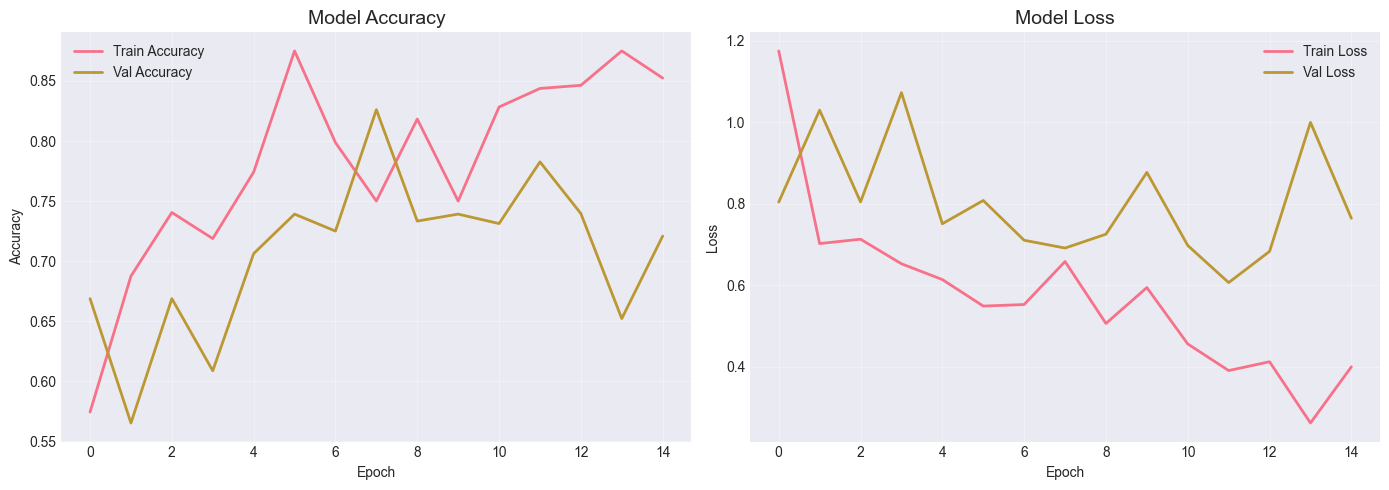


📊 Final Results:
   Train Accuracy: 0.8524
   Val Accuracy: 0.7208


In [ ]:
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy', linewidth=2)
plt.plot(history.history['val_accuracy'], label='Val Accuracy', linewidth=2)
plt.title('Model Accuracy', fontsize=14)
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss', linewidth=2)
plt.plot(history.history['val_loss'], label='Val Loss', linewidth=2)
plt.title('Model Loss', fontsize=14)
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# แสดงผล accuracy สุดท้าย
print(f"\n📊 Final Results:")
print(f"   Train Accuracy: {history.history['accuracy'][-1]:.4f}") 
print(f"   Val Accuracy: {history.history['val_accuracy'][-1]:.4f}") 

In [33]:
print("🔧 Fine-tuning base model...")

# Unfreeze base model
base_model.trainable = True
for layer in base_model.layers[:-30]:
    layer.trainable = False

model.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

history_fine = model.fit(
    train_generator,
    epochs=5,
    validation_data=validation_generator
)

print("✓ Fine-tuning completed!")

🔧 Fine-tuning base model...
Epoch 1/5
64/64 ━━━━━━━━━━━━━━━━━━━━ 173s 3s/step - accuracy: 0.7515 - loss: 0.7112 - val_accuracy: 0.7177 - val_loss: 0.9818
Epoch 2/5
64/64 ━━━━━━━━━━━━━━━━━━━━ 170s 3s/step - accuracy: 0.8479 - loss: 0.4184 - val_accuracy: 0.6958 - val_loss: 1.0548
Epoch 3/5
64/64 ━━━━━━━━━━━━━━━━━━━━ 169s 3s/step - accuracy: 0.8977 - loss: 0.3165 - val_accuracy: 0.7097 - val_loss: 0.9493
Epoch 4/5
64/64 ━━━━━━━━━━━━━━━━━━━━ 167s 3s/step - accuracy: 0.9280 - loss: 0.2227 - val_accuracy: 0.7495 - val_loss: 0.8599
Epoch 5/5
64/64 ━━━━━━━━━━━━━━━━━━━━ 165s 3s/step - accuracy: 0.9451 - loss: 0.1744 - val_accuracy: 0.7376 - val_loss: 1.0779
✓ Fine-tuning completed!


In [36]:
model.save("models/mobilenetv2_model.keras")
print("✅ MobileNetV2 model saved")

✅ MobileNetV2 model saved
